In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import os
import math
import numpy as np

import sys
sys.path.append('../../bgc-analysis')
from db_api import get_metadata_all
from  calc_sensor import pH_sbe, o2_sbe
sys.path.clear
sys.path.append('C:/Users/athay/OneDrive/Documents/Repositories/test-analysis')
from get_cal_sn import get_cal

In [5]:
lastdate = '20240223'  # SET AS THE LAST DAY THAT THE SPECIFIC FLOW THROUGH TEST WAS RUNNING


In [7]:
root = r"G://Shared drives//WHOI Argo//BGC//Float Tracking//flow_through_data//" + str(lastdate) + "//" # WHERE TO GET THE DATA FROM
files = [x for x in os.listdir(root) if x.endswith(".pkl")] # GETTING ALL pkl FILES

In [11]:
# SETTING UP DATAFRAME

data = pd.DataFrame(columns=['DATE', 'SN', 'PRES', 'TEMP', 'PSAL', 'O2_PHASE_DELAY',
       'O2_TEMPERATURE_VOLTAGE', 'MCOMS1', 'MCOMS2', 'MCOMS3', 'PH_VRS1', 'PH_VRS', 'PH_VK', 'PHIB', 'PHIK', 'PHVIN', 'PHVOUT', 'NITRATE'])
#ADDING DATA FROM ALL FILES INTO ONE BIG DATAFRAME
for file in files:
    data = pd.concat([data,pd.read_pickle(root+'/'+file)])
data = data.sort_values('DATE')
data['DATE'] = data['DATE'].dt.round('1s')
data = data.reset_index()
print(data)


C:\Users\athay\AppData\Local\Temp\ipykernel_11960\199256386.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,pd.read_pickle(root+'/'+file)])


      index                DATE    SN  PRES     TEMP    PSAL  O2_PHASE_DELAY  \
0         0 2024-02-23 11:50:08  1566  -0.4  21.3751  30.991          17.034   
1         0 2024-02-23 11:51:10  1635  -0.3  21.3240  30.972          16.994   
2         1 2024-02-23 11:51:31  1566  -0.4  21.3744  30.991          17.035   
3         1 2024-02-23 11:52:33  1635  -0.3  21.3309  30.973          16.991   
4         2 2024-02-23 11:52:54  1566  -0.4  21.3886  30.992          17.036   
...     ...                 ...   ...   ...      ...     ...             ...   
1077    182 2024-02-23 16:02:45  1635  -0.3  21.9254  31.067          16.991   
1078    178 2024-02-23 16:02:52  1633  -0.3  22.0369  31.073          16.988   
1079    179 2024-02-23 16:03:01  1583  -0.4  21.9752  31.080          17.289   
1080    183 2024-02-23 16:03:04  1566  -0.4  22.0879  31.067          17.031   
1081    177 2024-02-23 16:03:45  1634  -0.3  22.1812  31.061          16.904   

      O2_TEMPERATURE_VOLTAGE  MCOMS1   

In [12]:
# SPLIT UP DATA BY FLOAT AND CALCULATE PH AND OXYGEN 

fnum = []
for sn in data.SN.unique():
    sn = str(sn)
    cal = get_cal(sn)
    sub = data.loc[data.SN == sn,:]
    #PH
    PH_FREE, data.loc[data.SN ==sn, 'PH_TOTAL'] = pH_sbe(cal['TRANSISTOR_PH']['PREDEPLOYMENT_CALIB_COEFFICIENT'],sub.PH_VRS, sub.PRES, sub.TEMP, sub.PSAL)
    #Oxygen
    data.loc[data.SN==sn, 'DOXY'] = (o2_sbe(cal['OPTODE_DOXY']['PREDEPLOYMENT_CALIB_COEFFICIENT'], sub.O2_PHASE_DELAY, sub.O2_TEMPERATURE_VOLTAGE, sub.PRES, sub.TEMP, sub.PSAL)[0])
    fnum.append(sn)


In [13]:
data.to_excel('G://Shared drives/WHOI Argo/BGC/Float Tracking/flow_through_results/'  + lastdate + '_calcs_' + ".xlsx")


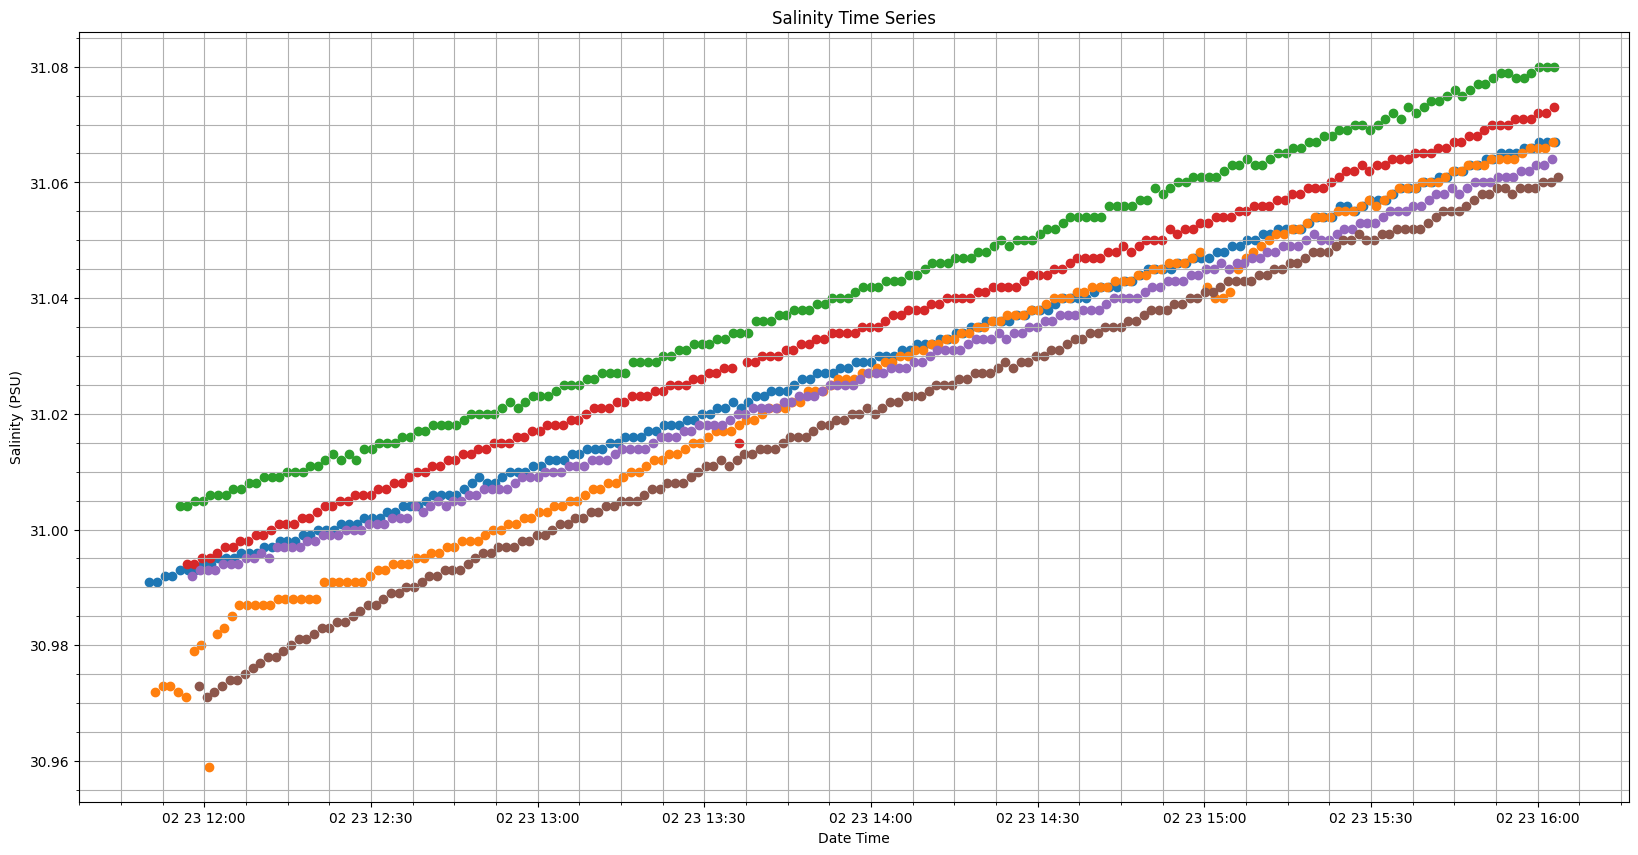

In [14]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['PSAL'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('Salinity Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('Salinity (PSU)')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

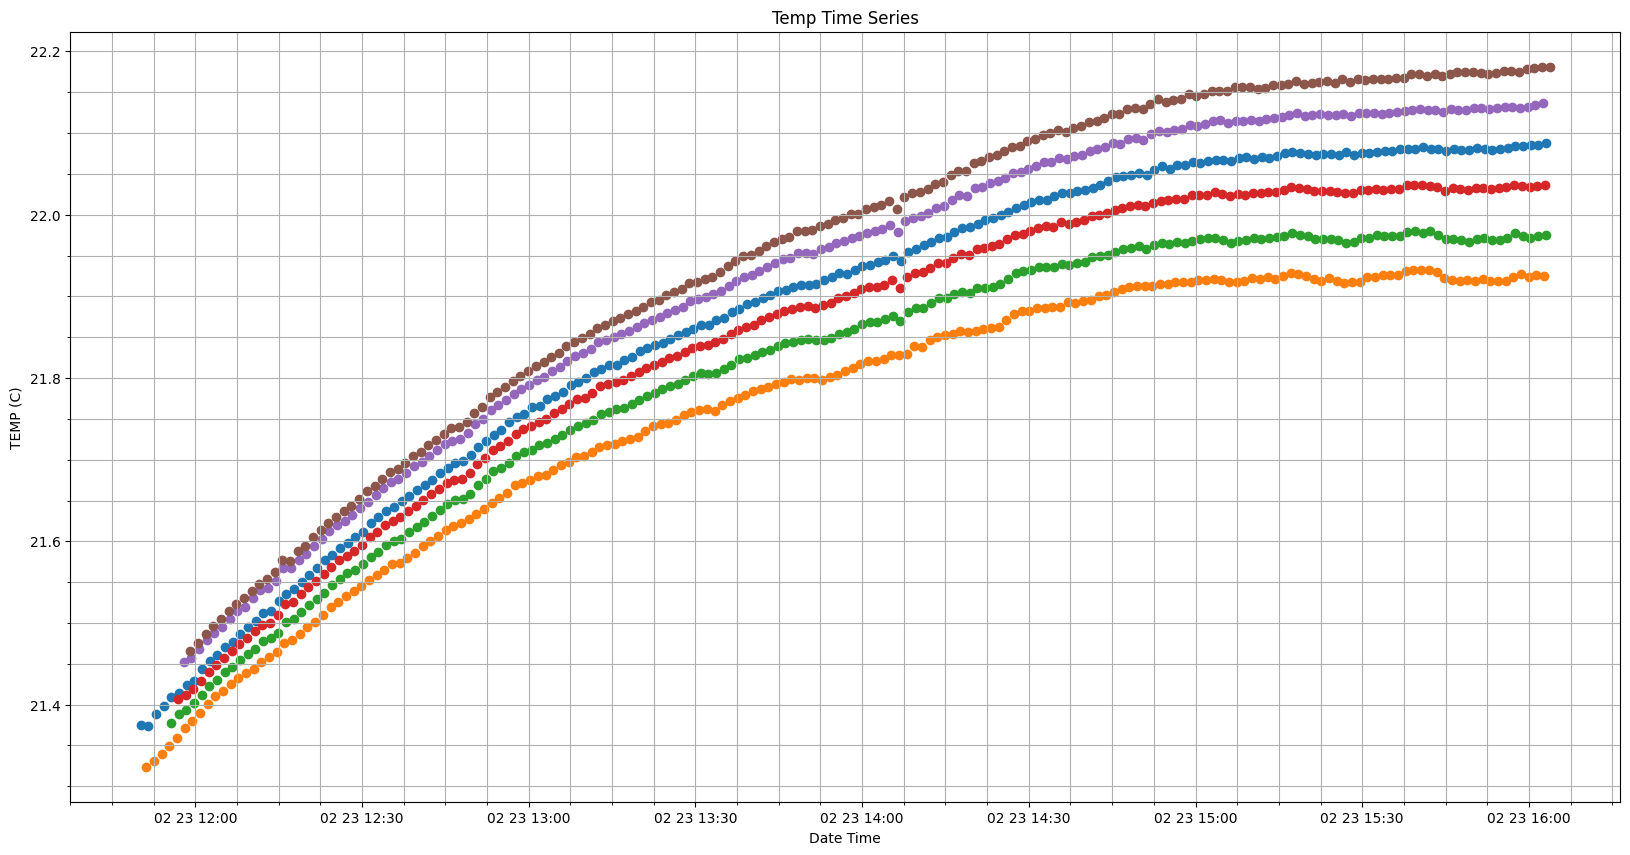

In [15]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['TEMP'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('Temp Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('TEMP (C)')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

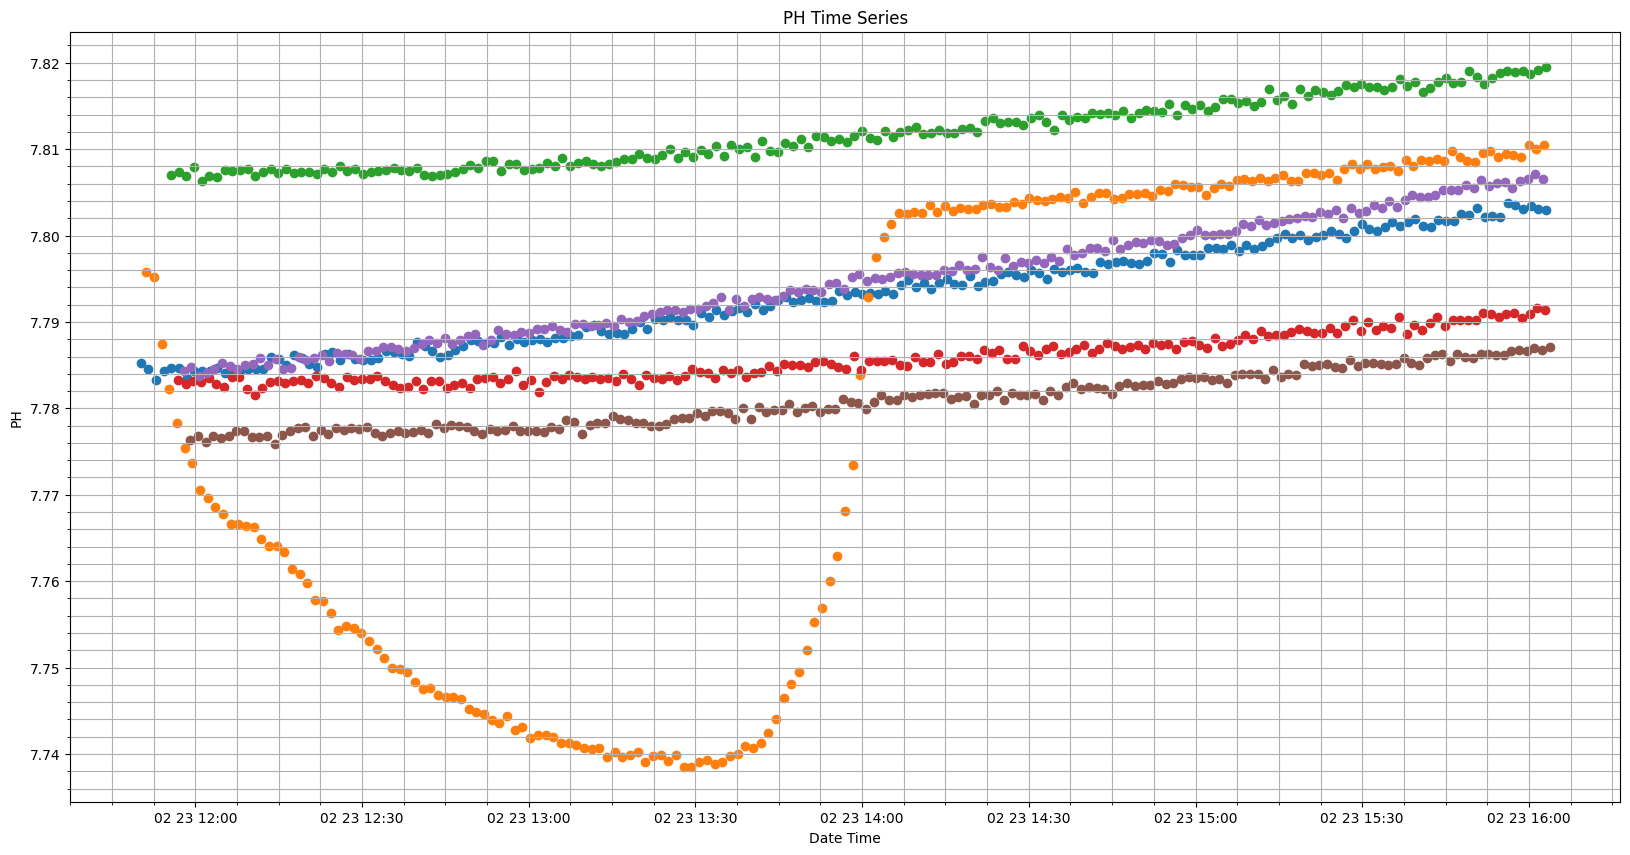

In [16]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['PH_TOTAL'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3]], loc = 'upper left')
pltt.set_title('PH Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('PH')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

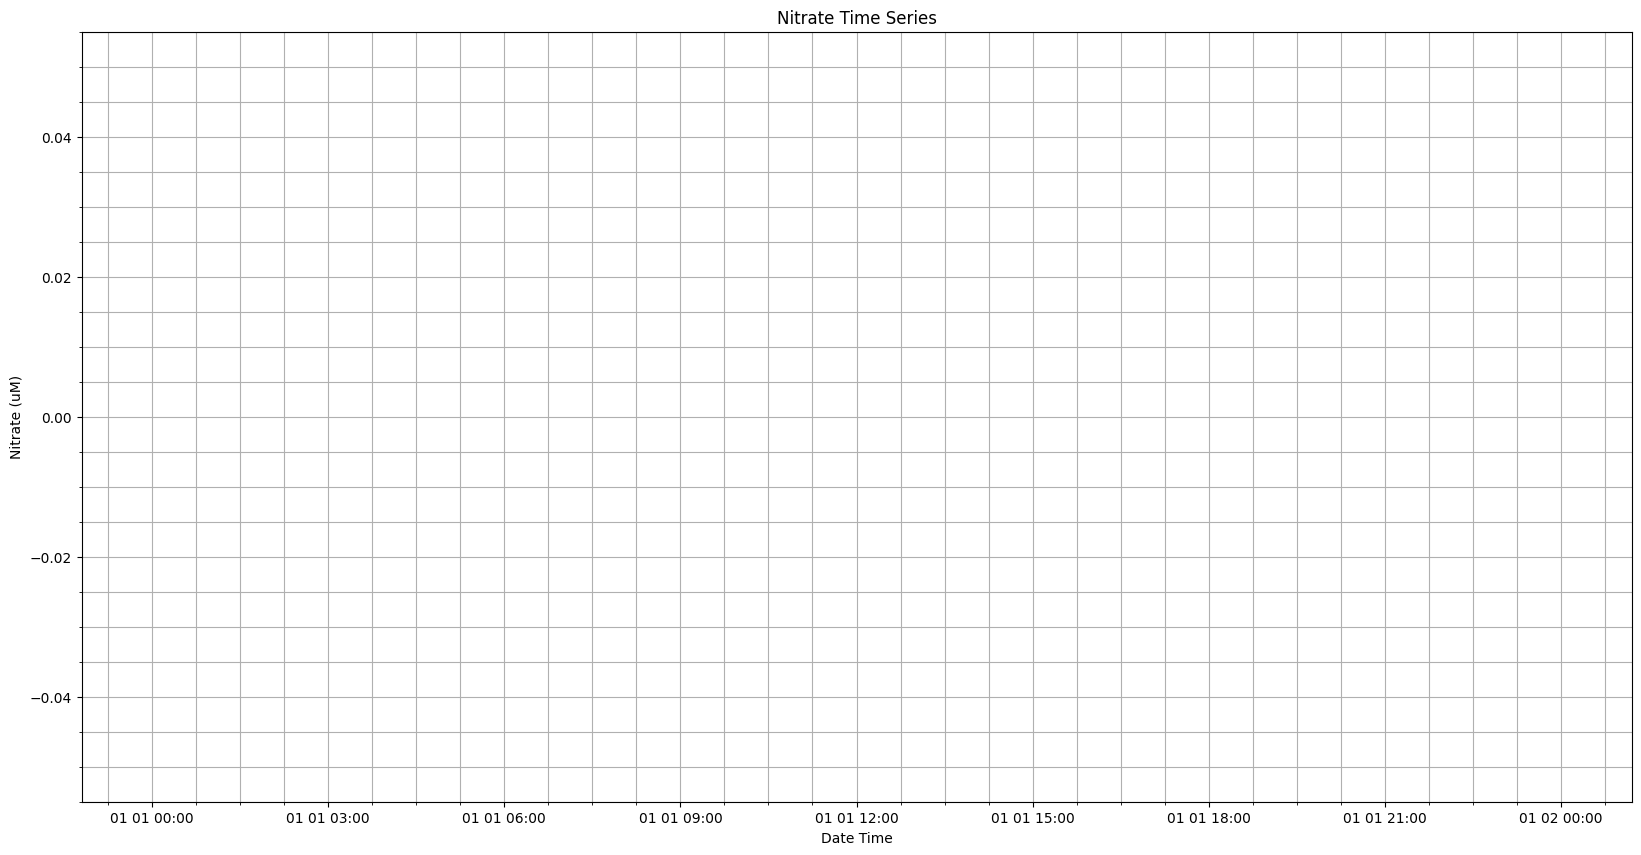

In [17]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['NITRATE'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('Nitrate Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('Nitrate (uM)')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')

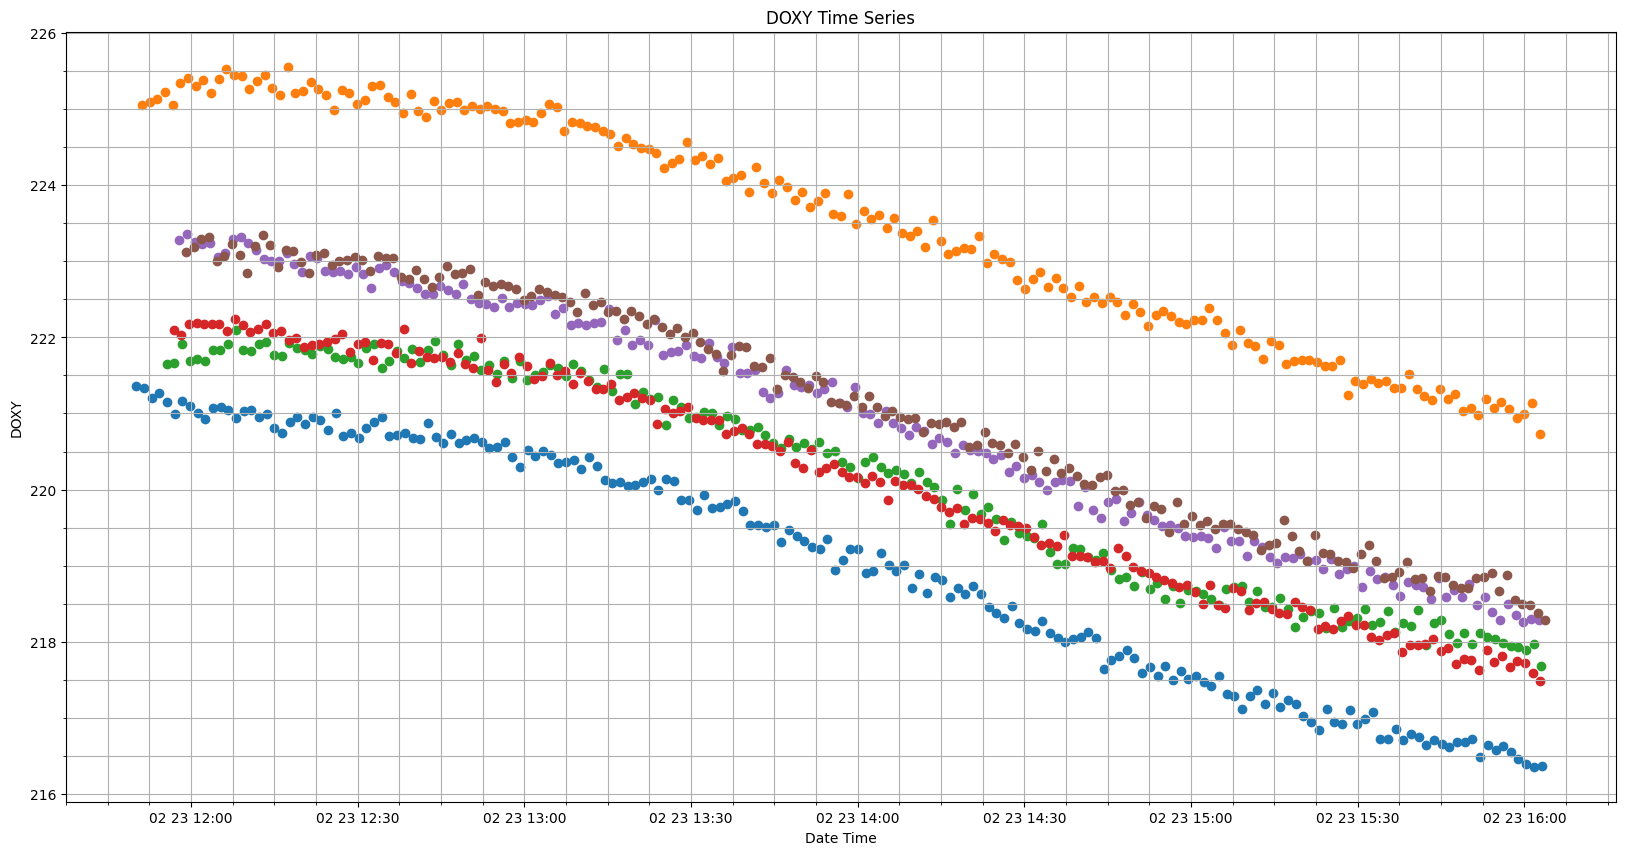

In [18]:
fig, pltt = plt.subplots(figsize = (20,10))
for sn in fnum:
    sub = data.loc[data.SN == sn]
    pltt.scatter(sub.DATE,sub['DOXY'])
dateFormat = DateFormatter("%m %d %H:%M")

#fig.legend([sns[0], sns[1], sns[2], sns[3],sns[4],sns[5]], loc = 'upper left')
pltt.set_title('DOXY Time Series')
pltt.set_xlabel('Date Time')
pltt.set_ylabel('DOXY')
pltt.xaxis.set_major_formatter(dateFormat)
pltt.minorticks_on()
pltt.grid(which='both')